# Binary Model Validation

This notebook is used to train and evaluate the binary model to predict fire occurrance based on humid data.

## 1. Import Necessary Libraries and Data Path

In [1]:
import os
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))

import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')

## 2. Data Preparation

In [2]:
print("\nPreparing data...")
merged_data, humid_cols = data_processor.prepare_weather_fire_data(
    data_type='binary', 
    weather_types=['humid']
)



Preparing data...

Data shape after merging:
Data shape: (1625, 30)
Data type selected: ['humid']


## 3. Split Dataset

In [4]:
from data_processor import split_dataset

print("\nBegin spliting data...")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data_processor.split_dataset(
    merged_data=merged_data,
    feature_columns=humid_cols,
    target_column='fire_binary'
)


Begin spliting data...
Data set splited successfully:
Training set size: 975 (60.00%)
Validating set size: 325 (20.00%)
Testing set size: 325 (20.00%)

Training set classification:
fire_binary
1    76.512821
0    23.487179
Name: proportion, dtype: float64

Validating set classification:
fire_binary
1    76.0
0    24.0
Name: proportion, dtype: float64

Testing set classification:
fire_binary
1    76.307692
0    23.692308
Name: proportion, dtype: float64


## 4. Pre-process Features 

In [5]:
from data_processor import preprocess_features

print("\nPre-processing features...")
X_train_processed, X_val_processed, X_test_processed = preprocess_features(X_train, X_val, X_test)


Pre-processing features...

Data pre-processing results:
Training set shape: (975, 29)
Validating set shape: (325, 29)
Testing set shape: (325, 29)

Check missing-values in the pre-processed data:
Missing value of training set: 0
Missing value of validating set: 0
Missing value of testing set: 0


## 5. Defing the Function to Train and Evaluate Two Models

In [6]:
def train_and_evaluate_models(X_train, X_val, y_train, y_val):
    
    # Model 1: Logistic Regression
    lr_model = LogisticRegression(random_state=42, max_iter=1000)
    lr_model.fit(X_train, y_train)
    lr_pred = lr_model.predict(X_val)
    lr_prob = lr_model.predict_proba(X_val)[:, 1]
    
    # Model 2: Random Forest
    rf_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    )
    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_val)
    rf_prob = rf_model.predict_proba(X_val)[:, 1]
    
    models = {
        'Logistic Regression': (lr_pred, lr_prob, lr_model),
        'Random Forest': (rf_pred, rf_prob, rf_model)
    }

    plt.figure(figsize=(10, 8))
    colors = ['blue', 'red']
    for (name, (pred, prob, model)), color in zip(models.items(), colors):
        fpr, tpr, _ = roc_curve(y_val, prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2,
                label=f'{name} (AUC = {roc_auc:.3f})')
    
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves Comparison')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    
    for name, (pred, prob, model) in models.items():
        print(f"\n{name} Evaluation:")
        print("\nClassification Results:")
        print(classification_report(y_val, pred))
        print("\nROC-AUC Scores:", roc_auc_score(y_val, prob))
        
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_val, pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f'{name} Confusion Matrix')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.show()
        
        plt.figure(figsize=(10, 6))
        if name == 'Random Forest':
            feature_importance = pd.DataFrame({
                'feature': X_train.columns,
                'importance': model.feature_importances_
            }).sort_values('importance', ascending=False)
            
            sns.barplot(data=feature_importance.head(10), x='importance', y='feature')
            plt.title('Random Forest Feature Importance (Top 10)')
            plt.xlabel('Importance Score')
        else:
            feature_weights = pd.DataFrame({
                'feature': X_train.columns,
                'coefficient': np.abs(model.coef_[0])
            }).sort_values('coefficient', ascending=False)
            
            sns.barplot(data=feature_weights.head(10), x='coefficient', y='feature')
            plt.title('Logistic Regression Absolute Coefficients (Top 10)')
            plt.xlabel('|Coefficient|')
        
        plt.ylabel('Feature')
        plt.tight_layout()
        plt.show()
    
    return models

## 6. Execute Model Training and Evaluation


Begin training and evaluating the models...


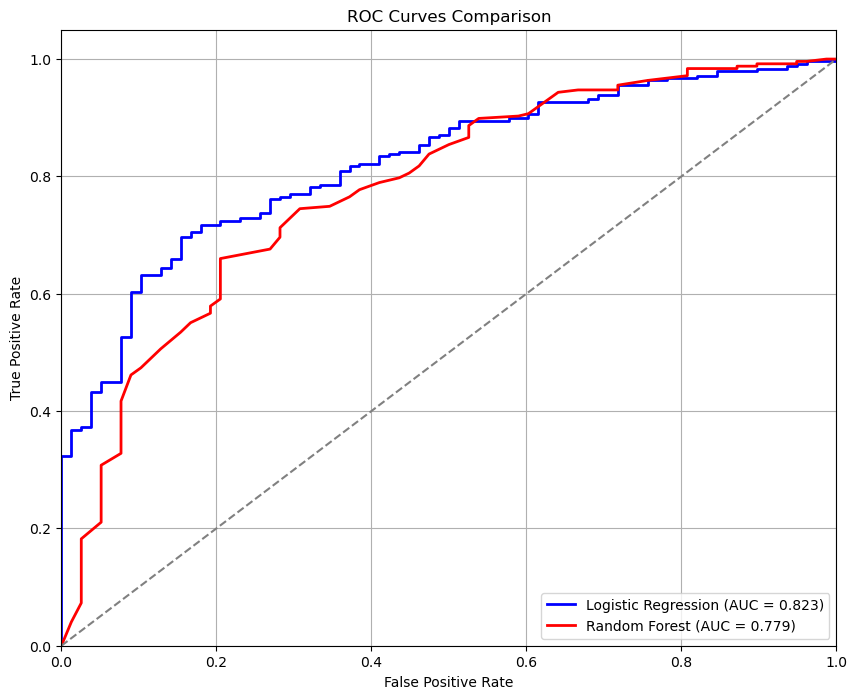


Logistic Regression Evaluation:

Classification Results:
              precision    recall  f1-score   support

           0       0.62      0.37      0.46        78
           1       0.82      0.93      0.87       247

    accuracy                           0.79       325
   macro avg       0.72      0.65      0.67       325
weighted avg       0.77      0.79      0.77       325


ROC-AUC Scores: 0.8229523512924323


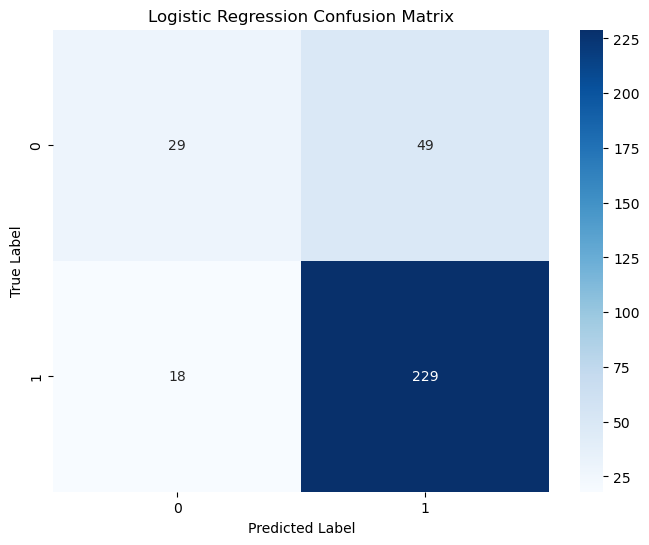

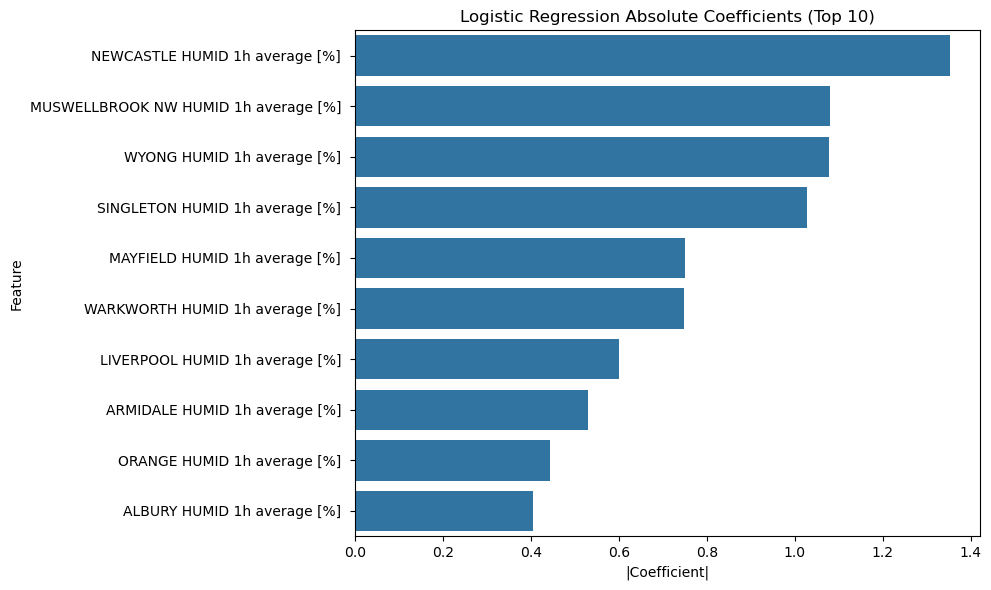


Random Forest Evaluation:

Classification Results:
              precision    recall  f1-score   support

           0       0.68      0.24      0.36        78
           1       0.80      0.96      0.88       247

    accuracy                           0.79       325
   macro avg       0.74      0.60      0.62       325
weighted avg       0.77      0.79      0.75       325


ROC-AUC Scores: 0.7789110349839095


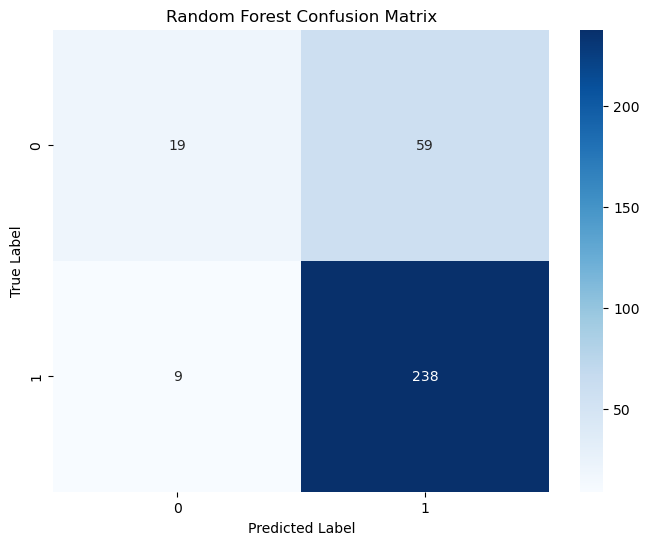

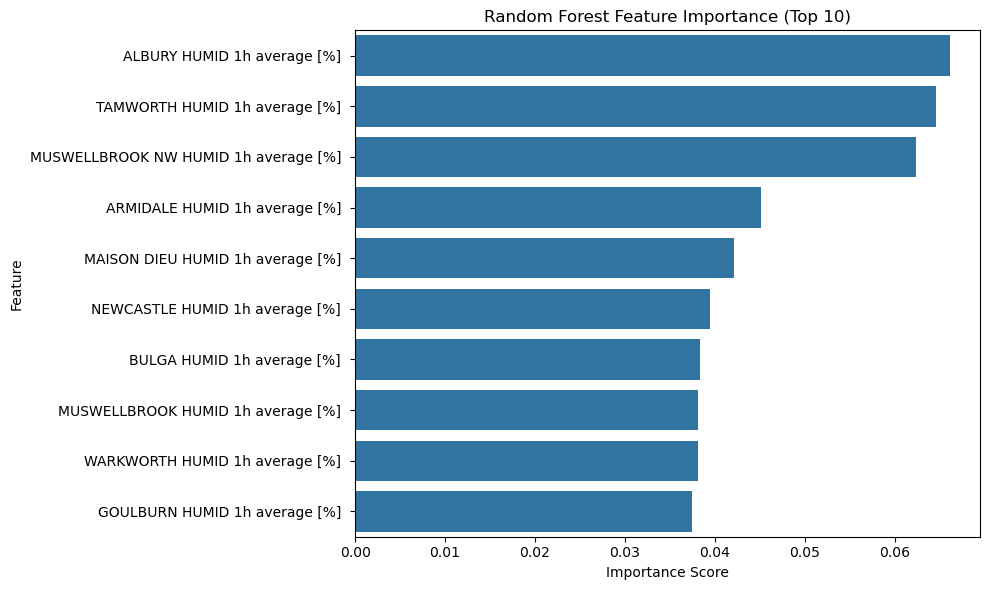

In [7]:
print("\nBegin training and evaluating the models...")
models = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val)